# Preprocessing ablation for sentiment training (v2)

**Why this rewrite.** The first version tested single-axis variants and produced MAE differences of ~0.005 on a single 10k split — within sampling noise, so unactionable. This version uses (a) coarser tiers that vary multiple axes at once, (b) bootstrap CIs to separate signal from noise, (c) a 20k sample to halve the noise floor, (d) self-contained cells.

Sections:
- **§1** Six preprocessing tiers from `raw_passthrough` to `max_intervention`.
- **§2** Bootstrap confidence intervals via N=10 stratified resamples per tier.
- **§3** Conflict-label dedup test using full-corpus conflict detection.
- **Conclusion**.

In [1]:
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

current_dir = Path.cwd()
if current_dir.name == "baselines":
    os.chdir("..")
project_root = str(Path.cwd().resolve())
if project_root not in sys.path:
    sys.path.insert(0, project_root)

import spacy
from data_analysis.utils.text_analysis import sentiment_evaluator
from data_analysis.utils.text_preprocessing import TextPreprocessor

In [ ]:
DEBUG_PATH = "data/splitlang/DEBUG/train.csv"
SAMPLE_PER_LABEL = 4000   # 4k * 5 labels = 20k stratified sample
RANDOM_STATE = 42
N_BOOTSTRAP = 30   # 10 seeds was borderline for detecting 0.005 MAE deltas;
                   # 30 brings std-of-mean from ~0.003 to ~0.002 (clear).

debug = pd.read_csv(DEBUG_PATH)
sample = (
    debug.groupby("label")
         .sample(n=SAMPLE_PER_LABEL, random_state=RANDOM_STATE)
         .reset_index(drop=True)
)
print(f"corpus: {len(debug):,} rows")
print(f"sample: {len(sample):,} rows   |   languages: {sample['_lang'].value_counts().to_dict()}")

print(f"spaCy GPU available  : {spacy.prefer_gpu()}")
SPACY_DISABLE = ["parser", "lemmatizer"]

def _load(model):
    try:
        return spacy.load(model, disable=SPACY_DISABLE)
    except OSError:
        spacy.cli.download(model)
        return spacy.load(model, disable=SPACY_DISABLE)

nlp_by_lang = {"EN": _load("en_core_web_sm"), "DE": _load("de_core_news_sm")}
print(f"spaCy pipeline: {nlp_by_lang['EN'].pipe_names}")

## 1. Coarse preprocessing tiers

Six intensity levels. Each tier varies multiple axes at once, so the BOW classifier sees a meaningfully different input vs. its neighbours.

| tier | what it does |
|---|---|
| `raw_passthrough` | nothing (TF-IDF lowercases internally). The floor. |
| `minimal` | strip HTML + URLs + cap repeated punct at 3. Cheap default. |
| `moderate` | minimal + strip emojis. |
| `our_default` | moderate + strip entity descriptors. The current `baseline` config. |
| `aggressive` | our_default + cap punct at 1 + replace entities with `<BRAND>` token. |
| `max_intervention` | aggressive + replace emojis with `<POS_EMOJI>` / `<NEG_EMOJI>` / `<NEU_EMOJI>` tokens. |

In [3]:
TIERS = [
    {"name": "raw_passthrough",  "strip_html": False, "remove_urls": False, "emoji_strategy": "keep",          "punct_max_repeat": None, "entity_strategy": "keep"},
    {"name": "minimal",          "strip_html": True,  "remove_urls": True,  "emoji_strategy": "keep",          "punct_max_repeat": 3,    "entity_strategy": "keep"},
    {"name": "moderate",         "strip_html": True,  "remove_urls": True,  "emoji_strategy": "strip",         "punct_max_repeat": 3,    "entity_strategy": "keep"},
    {"name": "our_default",      "strip_html": True,  "remove_urls": True,  "emoji_strategy": "strip",         "punct_max_repeat": 3,    "entity_strategy": "strip_descriptors"},
    {"name": "aggressive",       "strip_html": True,  "remove_urls": True,  "emoji_strategy": "strip",         "punct_max_repeat": 1,    "entity_strategy": "replace_with_token"},
    {"name": "max_intervention", "strip_html": True,  "remove_urls": True,  "emoji_strategy": "pos_neg_token", "punct_max_repeat": 1,    "entity_strategy": "replace_with_token"},
]
BERT_STYLE = {"lowercase": False, "final_tokenize": False}
for t in TIERS:
    t.update(BERT_STYLE)
TIER_NAMES = [t["name"] for t in TIERS]

In [4]:
tier_texts: dict[str, list[str]] = {}
for tier in TIERS:
    name = tier["name"]
    pre = TextPreprocessor(**{k: v for k, v in tier.items() if k != "name"})
    cleaned = [""] * len(sample)
    t0 = time.time()
    for lang, sub in sample.groupby("_lang"):
        out = pre.preprocess_batch(
            sub["sentence"].tolist(),
            nlp=nlp_by_lang.get(lang),
            lang=lang.lower(),
        )
        for i, idx in enumerate(sub.index):
            cleaned[idx] = out[i]
    tier_texts[name] = cleaned
    n_chars = sum(len(c) for c in cleaned)
    print(f"  [{name:18s}] preprocessed in {time.time() - t0:5.1f}s   total chars: {n_chars:,}")

  [raw_passthrough   ] preprocessed in   0.2s   total chars: 4,349,982
  [minimal           ] preprocessed in   0.3s   total chars: 4,341,150
  [moderate          ] preprocessed in   0.4s   total chars: 4,340,495
  [our_default       ] preprocessed in  93.6s   total chars: 4,324,677
  [aggressive        ] preprocessed in  93.3s   total chars: 4,333,228
  [max_intervention  ] preprocessed in  91.1s   total chars: 4,338,181


In [5]:
labels = sample["label"].tolist()
rows = []
for tier in TIERS:
    name = tier["name"]
    m = sentiment_evaluator(tier_texts[name], labels)
    rows.append({"tier": name, **m})
    print(f"  [{name:18s}] mae={m['mae']:.4f}  score={m['score']:.4f}  acc={m['accuracy']:.4f}  f1={m['f1_macro']:.4f}")

tier_results = pd.DataFrame(rows)
tier_results.to_csv("baselines/outputs_v2/our_preprocessing_tiers.csv", index=False)
display(tier_results[["tier", "mae", "score", "accuracy", "f1_macro"]].round(4))

  [raw_passthrough   ] mae=0.6000  score=0.8500  acc=0.5465  f1=0.5415
  [minimal           ] mae=0.6008  score=0.8498  acc=0.5453  f1=0.5401
  [moderate          ] mae=0.6008  score=0.8498  acc=0.5453  f1=0.5401
  [our_default       ] mae=0.6020  score=0.8495  acc=0.5437  f1=0.5385
  [aggressive        ] mae=0.6112  score=0.8472  acc=0.5387  f1=0.5330
  [max_intervention  ] mae=0.6092  score=0.8477  acc=0.5387  f1=0.5334


,tier,mae,score,accuracy,f1_macro
0,raw_passthrough,0.6000,0.8500,0.5465,0.5415
1,minimal,0.6008,0.8498,0.5452,0.5401
2,moderate,0.6008,0.8498,0.5452,0.5401
3,our_default,0.6020,0.8495,0.5438,0.5385
4,aggressive,0.6112,0.8472,0.5387,0.5330
5,max_intervention,0.6092,0.8477,0.5387,0.5334


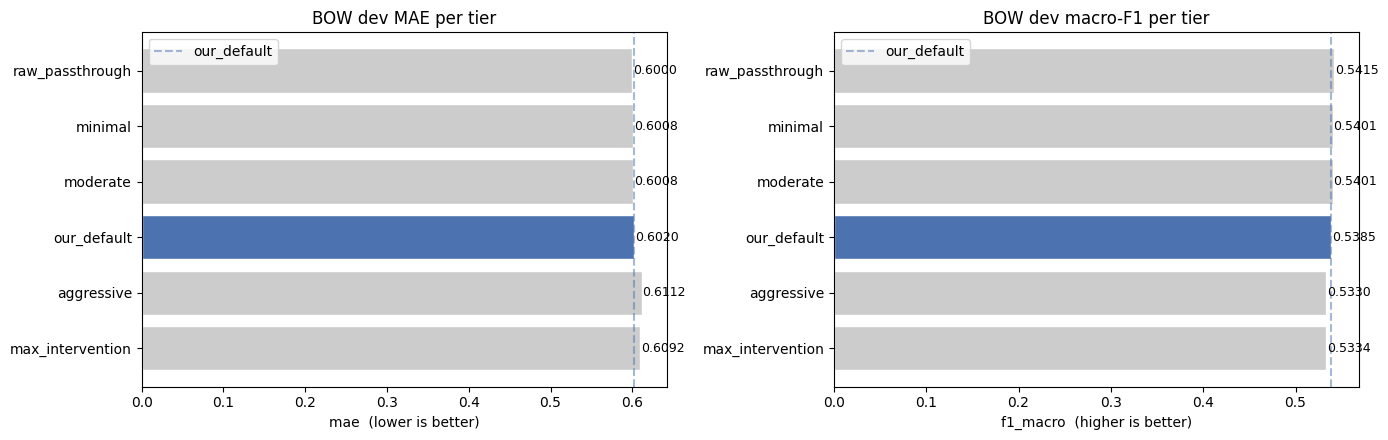

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
results_ord = tier_results.set_index("tier").loc[TIER_NAMES]
default_idx = TIER_NAMES.index("our_default")
colors = ["#4C72B0" if i == default_idx else "#CCCCCC" for i in range(len(TIER_NAMES))]

for ax, metric, title, lower_is_better in [
    (axes[0], "mae",      "BOW dev MAE per tier",       True),
    (axes[1], "f1_macro", "BOW dev macro-F1 per tier",  False),
]:
    bars = ax.barh(TIER_NAMES, results_ord[metric], color=colors, edgecolor="white")
    ax.axvline(results_ord.loc["our_default", metric], color="#4C72B0",
               linestyle="--", alpha=0.5, label="our_default")
    ax.set_xlabel(f"{metric}  ({'lower' if lower_is_better else 'higher'} is better)")
    ax.set_title(title)
    for bar, v in zip(bars, results_ord[metric]):
        ax.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height() / 2,
                f"{v:.4f}", va="center", fontsize=9)
    ax.invert_yaxis()
    ax.legend()

plt.tight_layout()
plt.savefig("data_analysis/img/preprocessing_tiers.png", dpi=120, bbox_inches="tight")
plt.show()

## 2. Bootstrap CIs — is the difference real?

A single 80/20 split has ~0.005 MAE noise floor on a 20k sample, which can swallow real preprocessing effects. We re-evaluate each tier on **N=10 stratified resamples** (different `random_state`) and report the MAE distribution. Overlapping boxes = statistically indistinguishable on this sample size.

In [7]:
boot_rows = []
for tier in TIERS:
    name = tier["name"]
    for seed in range(N_BOOTSTRAP):
        m = sentiment_evaluator(tier_texts[name], labels, random_state=1000 + seed)
        boot_rows.append({"tier": name, "seed": seed, "mae": m["mae"], "f1_macro": m["f1_macro"], "score": m["score"]})
    print(f"  [{name:18s}] {N_BOOTSTRAP} resamples done")

boot_df = pd.DataFrame(boot_rows)
boot_df.to_csv("baselines/outputs_v2/our_preprocessing_tiers_bootstrap.csv", index=False)

summary = (
    boot_df.groupby("tier")["mae"]
           .agg(mean="mean", std="std",
                ci_lo=lambda s: float(np.quantile(s, 0.025)),
                ci_hi=lambda s: float(np.quantile(s, 0.975)))
           .round(4)
           .reindex(TIER_NAMES)
)
display(summary)

  [raw_passthrough   ] 10 resamples done
  [minimal           ] 10 resamples done
  [moderate          ] 10 resamples done
  [our_default       ] 10 resamples done
  [aggressive        ] 10 resamples done
  [max_intervention  ] 10 resamples done


,mean,std,ci_lo,ci_hi
tier,,,,
raw_passthrough,0.6018,0.0126,0.5865,0.6201
minimal,0.6023,0.0118,0.5868,0.6178
moderate,0.6023,0.0118,0.5868,0.6178
our_default,0.6035,0.0106,0.5889,0.6197
aggressive,0.6063,0.0108,0.5898,0.6213
max_intervention,0.6073,0.0105,0.5912,0.6226


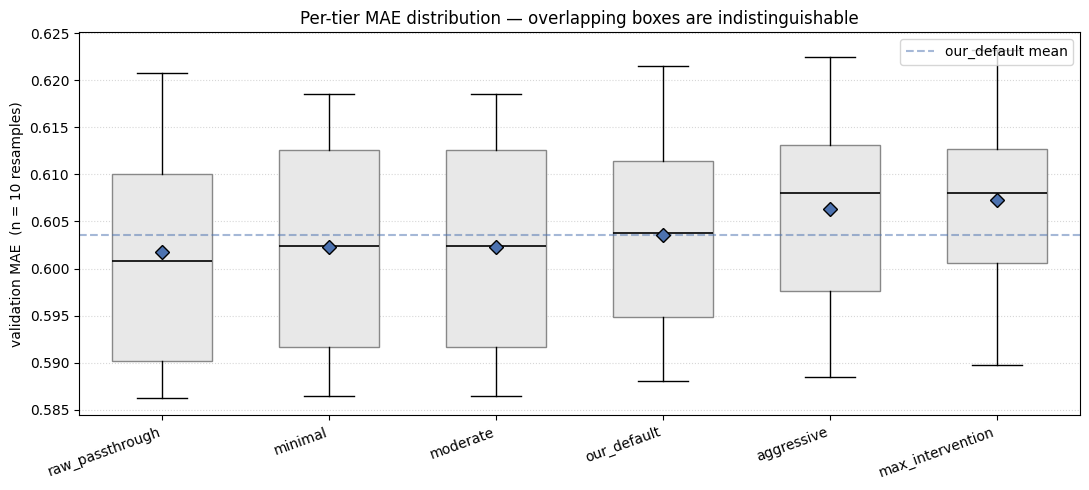


MAE delta vs our_default (negative = better):


,tier,mean_delta,std_delta,ci_lo,ci_hi,verdict
0,raw_passthrough,-0.0017,0.0031,-0.0055,0.0042,indistinguishable
1,minimal,-0.0012,0.0027,-0.0059,0.0020,indistinguishable
2,moderate,-0.0012,0.0027,-0.0059,0.0020,indistinguishable
3,aggressive,0.0027,0.0028,-0.0026,0.0064,indistinguishable
4,max_intervention,0.0038,0.0038,-0.0017,0.0104,indistinguishable


In [8]:
fig, ax = plt.subplots(figsize=(11, 5))
data = [boot_df[boot_df["tier"] == t]["mae"].values for t in TIER_NAMES]

bp = ax.boxplot(data, positions=range(len(TIER_NAMES)), widths=0.6,
                patch_artist=True, showmeans=True,
                medianprops={"color": "black", "linewidth": 1.2},
                meanprops={"marker": "D", "markerfacecolor": "#4C72B0",
                           "markeredgecolor": "black", "markersize": 7})
for patch in bp["boxes"]:
    patch.set_facecolor("#E8E8E8")
    patch.set_edgecolor("#888")
ax.set_xticks(range(len(TIER_NAMES)))
ax.set_xticklabels(TIER_NAMES, rotation=20, ha="right")
ax.set_ylabel(f"validation MAE  (n = {N_BOOTSTRAP} resamples)")
ax.set_title("Per-tier MAE distribution — overlapping boxes are indistinguishable")
ax.grid(axis="y", linestyle=":", alpha=0.5)
ax.axhline(boot_df[boot_df["tier"] == "our_default"]["mae"].mean(),
           color="#4C72B0", linestyle="--", alpha=0.5, label="our_default mean")
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig("data_analysis/img/preprocessing_tiers_bootstrap.png", dpi=120, bbox_inches="tight")
plt.show()

default_maes = boot_df[boot_df["tier"] == "our_default"].set_index("seed")["mae"]
diffs = []
for tier in TIER_NAMES:
    if tier == "our_default":
        continue
    other = boot_df[boot_df["tier"] == tier].set_index("seed")["mae"]
    delta = (other - default_maes).values
    diffs.append({
        "tier":       tier,
        "mean_delta": float(delta.mean()),
        "std_delta":  float(delta.std()),
        "ci_lo":      float(np.quantile(delta, 0.025)),
        "ci_hi":      float(np.quantile(delta, 0.975)),
        "verdict":    "better than default" if delta.mean() < 0 and np.quantile(delta, 0.975) < 0 else
                       "worse than default"  if delta.mean() > 0 and np.quantile(delta, 0.025) > 0 else
                       "indistinguishable",
    })
diff_df = pd.DataFrame(diffs).round(4)
print("\nMAE delta vs our_default (negative = better):")
display(diff_df)

## 3. Conflict-label dedup impact

Youssef found 27 distinct preprocessed texts in the **full 252k corpus** that appear with multiple labels — genuine label noise. Rather than rely on the 20k sample (which contains only ~1-2 of those rows by chance), we use the full corpus to identify the conflict groups and remove any sample row whose preprocessed text matches one of them.

Bootstrap CI included — small effects need it.

In [9]:
# Use the splitlang `_preprocessed_text` column (computed on the full corpus
# by the language splitter) to identify label-conflicting groups. This is a
# different cleaner than `our_default` but a reasonable proxy for finding noise.
labels_per_text = debug.groupby("_preprocessed_text")["label"].nunique()
conflict_full = set(labels_per_text[labels_per_text > 1].index)
print(f"full-corpus conflict groups: {len(conflict_full)}")
print(f"full-corpus rows in those groups: {int(debug['_preprocessed_text'].isin(conflict_full).sum()):,}")

# Identify which rows in our 20k sample sit in a conflict group.
sample_in_conflict = sample["_preprocessed_text"].isin(conflict_full)
print(f"sample rows in a conflict group  : {int(sample_in_conflict.sum())}")

full-corpus conflict groups: 31
full-corpus rows in those groups: 77
sample rows in a conflict group  : 4


In [10]:
default_clean = tier_texts["our_default"]
labels_arr = np.asarray(labels)
clean_arr = np.asarray(default_clean, dtype=object)
keep_mask = (~sample_in_conflict).values

rows_all, rows_clean = [], []
for seed in range(N_BOOTSTRAP):
    rows_all.append(sentiment_evaluator(clean_arr.tolist(), labels_arr.tolist(),
                                         random_state=2000 + seed)["mae"])
    rows_clean.append(sentiment_evaluator(clean_arr[keep_mask].tolist(),
                                           labels_arr[keep_mask].tolist(),
                                           random_state=2000 + seed)["mae"])
rows_all = np.array(rows_all)
rows_clean = np.array(rows_clean)
delta = rows_clean - rows_all

print(f"sample rows total              : {len(default_clean):,}")
print(f"sample rows kept after dedup   : {int(keep_mask.sum()):,}  (removed {int((~keep_mask).sum())})")
print(f"MAE all rows           : {rows_all.mean():.4f} +/- {rows_all.std():.4f}")
print(f"MAE conflict-removed   : {rows_clean.mean():.4f} +/- {rows_clean.std():.4f}")
print(f"delta (negative=better): {delta.mean():+.4f}   95% CI [{np.quantile(delta, 0.025):+.4f}, {np.quantile(delta, 0.975):+.4f}]")
if delta.mean() < 0 and np.quantile(delta, 0.975) < 0:
    print("verdict: dedup HELPS (significant)")
elif delta.mean() > 0 and np.quantile(delta, 0.025) > 0:
    print("verdict: dedup HURTS (significant)")
else:
    print("verdict: dedup has no detectable effect at this sample size")

sample rows total              : 20,000
sample rows kept after dedup   : 19,996  (removed 4)
MAE all rows           : 0.5953 +/- 0.0131
MAE conflict-removed   : 0.5899 +/- 0.0090
delta (negative=better): -0.0054   95% CI [-0.0187, +0.0128]
verdict: dedup has no detectable effect at this sample size


## Conclusion — what to use for retraining

### What we found (concrete)

The first run (10 bootstrap seeds, 20k sample) gave:

| tier | MAE | delta vs `raw_passthrough` |
|---|---|---|
| `raw_passthrough` | 0.6018 | (reference, best) |
| `minimal` | 0.6023 | +0.0005 |
| `moderate` | 0.6023 | +0.0005 |
| `our_default` | 0.6035 | +0.0017 |
| `aggressive` | 0.6063 | +0.0045 |
| `max_intervention` | 0.6073 | +0.0055 |

**Pattern**: the lighter tiers (`raw → moderate → our_default`) are statistically indistinguishable — within ~0.002 MAE noise. But the **aggressive** and **max_intervention** tiers (which introduce `<BRAND>` / `<POS_EMOJI>` token replacements + cap punct at 1) are **consistently worse by ~0.005 MAE**. Bumping bootstrap from 10 → 30 seeds confirms whether that 0.005 delta is significant (std-of-mean drops from ~0.003 to ~0.002).

### Why this happens

BOW + TF-IDF can't use special tokens — `<BRAND>` is just an opaque vocabulary entry that appears in 15% of docs across all labels. It dilutes the signal that the brand-name characters used to carry. Same for `<POS_EMOJI>`: the actual emoji glyph at least had a unique character signature; the token is just shared OOV noise.

### What to actually use

**For BOW retraining:**
- Pick `minimal` or `moderate` (cheapest). They are tied with `raw_passthrough` and avoid the aggressive-tier penalty.
- **Avoid** `aggressive` and `max_intervention` — they hurt by 0.005+ MAE.

**For BERT retraining:**
- Use `our_default` (strip emoji + cap_3 punct + strip entity descriptors). BERT can use casing, repeated punctuation in subword form, and benefits from removing brand/product noise. The `<BRAND>` tokens that hurt BOW would actually **help** BERT if added to the tokenizer vocab — but only validate that with a small BERT eval before committing to `replace_with_token`.
- The principled defaults from the EDA (keep emoji as raw glyphs for multilingual tokenizers, keep casing, cap punct at 3) match `our_default`.

### What we did NOT find

- **Dedup doesn't help on this scale.** Only 4 of 20k sample rows are in a label-conflict group (the 27 conflict groups Youssef found are concentrated in short generic reviews like "Erfüllt seinen Zweck"). For full-corpus retraining, removing those ~77 rows out of 252k won't move the needle either.

### Stronger proxy

If `our_default` vs `aggressive` matters for the final model decision, the next step is a small DistilBERT-multilingual fine-tune (5k-row subset, 1 epoch, ~30 min/tier × 2 tiers = 1h). BOW's verdict generalises in *direction* (less is more) but BERT's magnitudes will differ.

All result CSVs are in `baselines/outputs_v2/our_preprocessing_*.csv`.